# M03 — Magnetic survey admission and spatial holdout

**Question:** How does a spatially blocked M03 plan prevent geometry leakage while leaving magnetic corrections and inversion unresolved?

**Level 2 · Prerequisites: foundations notebook; read time: 25 minutes.**



## Objectives

Run the strict product parser and geometry planner on the committed authored 288-row protocol fixture. It has no measured magnetic response. A separate analytic synthetic control executes harmonic upward continuation. A second controlled CSV experiment runs the actual M03 flight-line processor, including height QC, tie-line crossovers, blocked-line scoring and supported gridding. Neither experiment is field evidence.


## Setup

Use the already reviewed Python 3.12 pipeline environment. This notebook installs nothing. It imports the repository parser, geometry planner, magnetic flight-line processor and continuation implementation directly. Generated CSV files are written only under the external `CAOS_TEMP_ROOT` used by the notebook runner.


In [1]:
import runpy, sys
from pathlib import Path

root = Path.cwd().parents[2]
sys.path.insert(0, str(root / "data-pipeline"))
from magnetic_survey_json import parse_request
from magnetic_survey import plan_geometry

support = runpy.run_path(str(root / "tests/data/magnetic_survey_support.py"))
# Verify the actual planner's source location.
print(Path(__import__("magnetic_survey").__file__).name)


magnetic_survey.py


## Data

The planner experiment uses the committed 288-row geometry fixture, which contains no measured magnetic response. The continuation experiment generates an analytic periodic harmonic field with known truth. The flight-line processor experiment authors a separate synthetic total-field survey with eight flight lines, a crossing tie line, small seeded noise, a deliberate tie offset and a height outlier. Its exact source bytes are hashed by the shared CSV adapter. All controls are explicitly synthetic.

**Files:** `tests/data/magnetic_survey_support.py`, `tests/fixtures/magnetic_survey/generate.py`, `data-pipeline/magnetic_survey.py`, `data-pipeline/magnetic_continuation.py`, `data-pipeline/magnetic_processing.py`, `docs/design/features/m03-flightline-processing/requirements.md`.


## Method

The survey planner fixes ENU metres, source/flight grouping, deterministic spatial blocks, an outer holdout and buffered folds. Rows sharing group or block stay together; rank and coverage are checked before likelihood materialization. This controls spatial leakage but does not correct diurnal variation, IGRF, altitude or provider grids.

The separate line processor requires an explicit one-to-one CSV map and source/frame declarations. It flags robust sensor-height outliers without changing observations, interpolates field values at geometric flight/tie intersections without leveling, reserves a contiguous whole-flight-line block, scores only supported held-out predictions, and grids fit-flight values with SciPy `LinearNDInterpolator`. Cells outside the Delaunay convex hull are masked. Grid spacing samples the same interpolant and does not change its held-out score. No correction, provider equivalence or inverse model is asserted.

The planner fixture provides east/north/up coordinates in metres, flight-group IDs, an explicit spatial block width and a 200 m buffer. The planner unions rows sharing either a flight group or a spatial block; transitive connections form indivisible units. It deterministically orders those units, holds out roughly one fifth for outer evaluation, then creates development folds. For each fold, fit rows within distance b of a validation or outer row are removed: retain i only if minⱼ∈H ‖xᵢ−xⱼ‖₂>b. This is a leakage-control rule, not a magnetic correction. Verde’s spatial train/test splitting is the related reference [API](https://www.fatiando.org/verde/latest/api/generated/verde.train_test_split.html).

The planner also checks geometric rank: for centered horizontal coordinates X=[1,e−ē,n−n̄], rank(X)=3 is required so the split is not collapsed to a line. This checks coordinate support, not field-property identifiability. The fixture has twelve flight lines and 288 positions but zero magnetic response. The figure shows exact row membership from fold 1, including buffered exclusions. Current eligibility explicitly withholds online/full-method acceptance because licensing, lineage, a validated likelihood and optimizer binding are unresolved.

Execute the product method on the declared control.


In [2]:
raw = support["encode"](support["request"]())
# Validate exact serialized bytes and compute the deterministic geometry seal.
handle = parse_request(raw)
plan = plan_geometry(handle)
print(
    {
        "schema": handle.metadata()["schema"],
        "partition_sha256": plan["partition"]["sha256"],
        "outer_rows": len(plan["partition"]["outer_rows"]["data"]),
        "folds": len(plan["partition"]["folds"]),
        "inverse_run": False,
    }
)


{'schema': 'magnetic-survey-inversion-1', 'partition_sha256': '18c36c658217ee39da1c3cdda336389f4b0a0d8115c928b6707a114e1753e12e', 'outer_rows': 72, 'folds': 3, 'inverse_run': False}


Blocked spatial splitting is preferable to random point splits for correlated flight lines. Verde documents spatial train/test splitting ([API reference](https://www.fatiando.org/verde/latest/api/generated/verde.train_test_split.html)); this product additionally seals group membership and buffers held-out rows. Current modules run only parser and geometry logic: no magnetic correction, kernel or optimizer.
Use the planner’s returned row indices directly. The chart is a map of the partition design, with physical coordinate axes in metres; its categories encode fit/holdout policy, never magnetic amplitude.


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Plot exact product-planner indices on the fixture's authored local geometry; colors denote partition role only.
meta = handle.metadata()
xyz = np.asarray(meta["geometry"]["receivers_m"]["data"], dtype=float).reshape(-1, 3)
outer = np.asarray(plan["partition"]["outer_rows"]["data"], dtype=int)
f = plan["partition"]["folds"][0]
fit = np.asarray(f["fit_rows"]["data"], dtype=int)
validation = np.asarray(f["validation_rows"]["data"], dtype=int)
buffered = np.asarray(f["buffered_rows"]["data"], dtype=int)
dev = set(plan["partition"]["development_rows"]["data"])
assert not (set(outer) & dev) and not (
    set(fit) & set(validation) or set(fit) & set(buffered) or set(validation) & set(buffered)
)


### Render the spatial split

The partition arrays have already been checked for overlap and leakage. This figure locates each actual planner row on the survey geometry; it does not imply that a magnetic response was measured or modeled.

{'outer': 72, 'fold_fit': 144, 'fold_validation': 72, 'buffered': 0, 'full_method_accepted': False, 'field_source_verified': False, 'geology_truth_known': False, 'online_admitted': False}


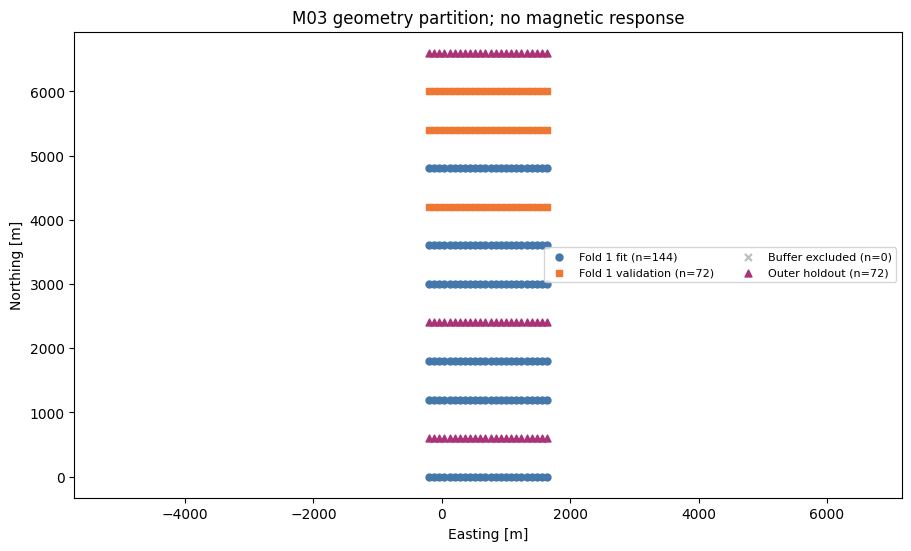

In [4]:
# Render the spatial split.
fig, ax = plt.subplots(figsize=(9, 5.4), constrained_layout=True)
for ids, label, color, marker in [
    (fit, "Fold 1 fit", "#4477aa", "o"),
    (validation, "Fold 1 validation", "#ee7733", "s"),
    (buffered, "Buffer excluded", "#bbbbbb", "x"),
    (outer, "Outer holdout", "#aa3377", "^"),
]:
    ax.scatter(xyz[ids, 0], xyz[ids, 1], label=f"{label} (n={len(ids)})", c=color, marker=marker, s=25)
ax.set(xlabel="Easting [m]", ylabel="Northing [m]", title="M03 geometry partition; no magnetic response")
ax.set_aspect("equal", adjustable="datalim")
ax.legend(ncol=2, fontsize=8)
print(
    {
        "outer": len(outer),
        "fold_fit": len(fit),
        "fold_validation": len(validation),
        "buffered": len(buffered),
        **plan["claims"],
    }
)
plt.show()


### Visual check of the encoded receiver geometry

This map shows the fixture’s receiver coordinates and labeled protocol groups before the planner is interpreted. It can reveal coordinate ordering or a misplaced block, but every response value is zero by construction. The view therefore supports a geometry and serialization check only; it cannot show magnetic anomalies, survey coverage quality, or predictive separation.


In [5]:
# Reparse the exact same request bytes as a separate step.
handle_repeat = parse_request(raw)
print(handle_repeat.metadata()["observations"]["values_sha256"])


71c642b31e5890a15ef92f3cbeba34edfb6e2e9f63079ecbda13a89d426f7d8b


Recompute the sealed geometry plan and check determinism.

In [6]:
# Recompute the sealed geometry plan and check determinism.
plan_repeat = plan_geometry(handle_repeat)
print(plan_repeat["partition"]["sha256"] == plan["partition"]["sha256"])


True


Hash the canonical partition identity returned by the pipeline.

In [7]:
# Hash the canonical partition identity returned by the pipeline.
from magnetic_survey_json import digest

print(digest(plan["partition"]))


e9393ca2a06106e09bc26583f7d26d23c784788df0beecf3da3e34da1b61883e


A malformed request is a negative control, not a smaller fallback survey.

In [8]:
# A malformed request is a negative control, not a smaller fallback survey.
from magnetic_survey_json import InputError

try:
    parse_request(raw + b"x")
except InputError as error:
    print("refused:", error.code)


refused: type


The first map displays the planner-selected row roles at their actual east/north coordinates. This companion chart aggregates the same sealed fold records into counts, so it exposes how the outer holdout, fold validation and buffer exclusions reduce the usable training sample. Counts describe split geometry only; no magnetic response exists in this fixture, so they are not prediction skill or survey coverage.

Compare retained training, validation and buffered row counts across the planned folds.

{'Fold 1': {'fit': 144, 'validation': 72, 'buffered': 0}, 'Fold 2': {'fit': 144, 'validation': 72, 'buffered': 0}, 'Fold 3': {'fit': 144, 'validation': 72, 'buffered': 0}}


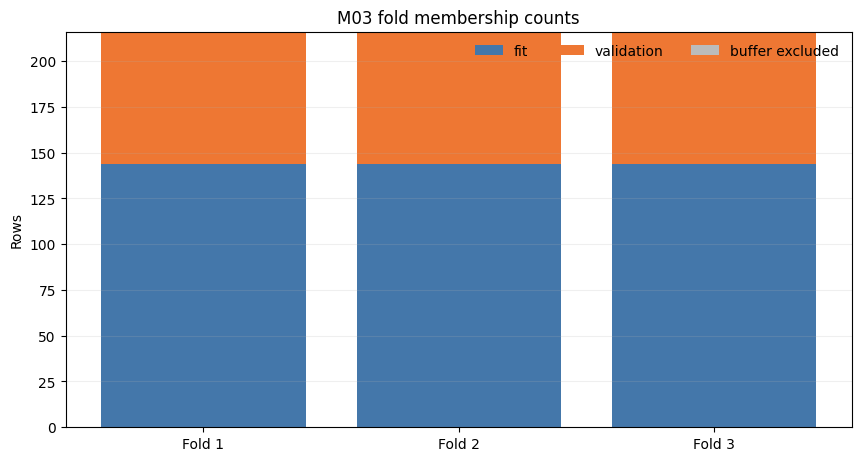

In [9]:
# Aggregate exact planner indices for each predeclared fold.
import numpy as np
import matplotlib.pyplot as plt

folds = plan["partition"]["folds"]
labels = [f"Fold {i + 1}" for i in range(len(folds))]
fit_n = [len(f["fit_rows"]["data"]) for f in folds]
validation_n = [len(f["validation_rows"]["data"]) for f in folds]
buffer_n = [len(f["buffered_rows"]["data"]) for f in folds]
x = np.arange(len(folds))
fig, ax = plt.subplots(figsize=(8.5, 4.5), constrained_layout=True)
ax.bar(x, fit_n, label="fit", color="#4477aa")
ax.bar(x, validation_n, bottom=fit_n, label="validation", color="#ee7733")
bottom = np.asarray(fit_n) + np.asarray(validation_n)
ax.bar(x, buffer_n, bottom=bottom, label="buffer excluded", color="#bbbbbb")
ax.set(xticks=x, xticklabels=labels, ylabel="Rows", title="M03 fold membership counts")
ax.legend(frameon=False, ncol=3)
ax.grid(axis="y", alpha=0.2)
print(
    {label: {"fit": a, "validation": b, "buffered": c} for label, a, b, c in zip(labels, fit_n, validation_n, buffer_n)}
)
plt.show()


These bars are direct counts from the planner’s serialized row indices, not a second split implementation. A large buffer can sharply reduce training rows, while validation counts remain fixed by the sealed fold; this trade-off is visible before any response or inverse is considered. The outer holdout is not included in these development-fold categories. The chart therefore helps audit whether the declared geometry design leaves enough development support, but cannot establish that a future magnetic estimator will generalize.

### Upward continuation: controlled spectral experiment

For a harmonic potential field in a source-free half-space, each horizontal Fourier mode at wavenumber magnitude \(k\) decays with height as \(e^{-kh}\). The experiment combines one known mode with an affine regional plane, continues it by 500 m, and checks both predictions against the analytic solution. The affine plane is retained because its Laplacian is zero. The FFT uses a periodic extension, so the displayed seam diagnostic must be considered when choosing a real survey window.

height=500 m; mode attenuation=0.014022; max analytic error=6.548e-11 nT
FFT seam ratio: 0.8228287049076314


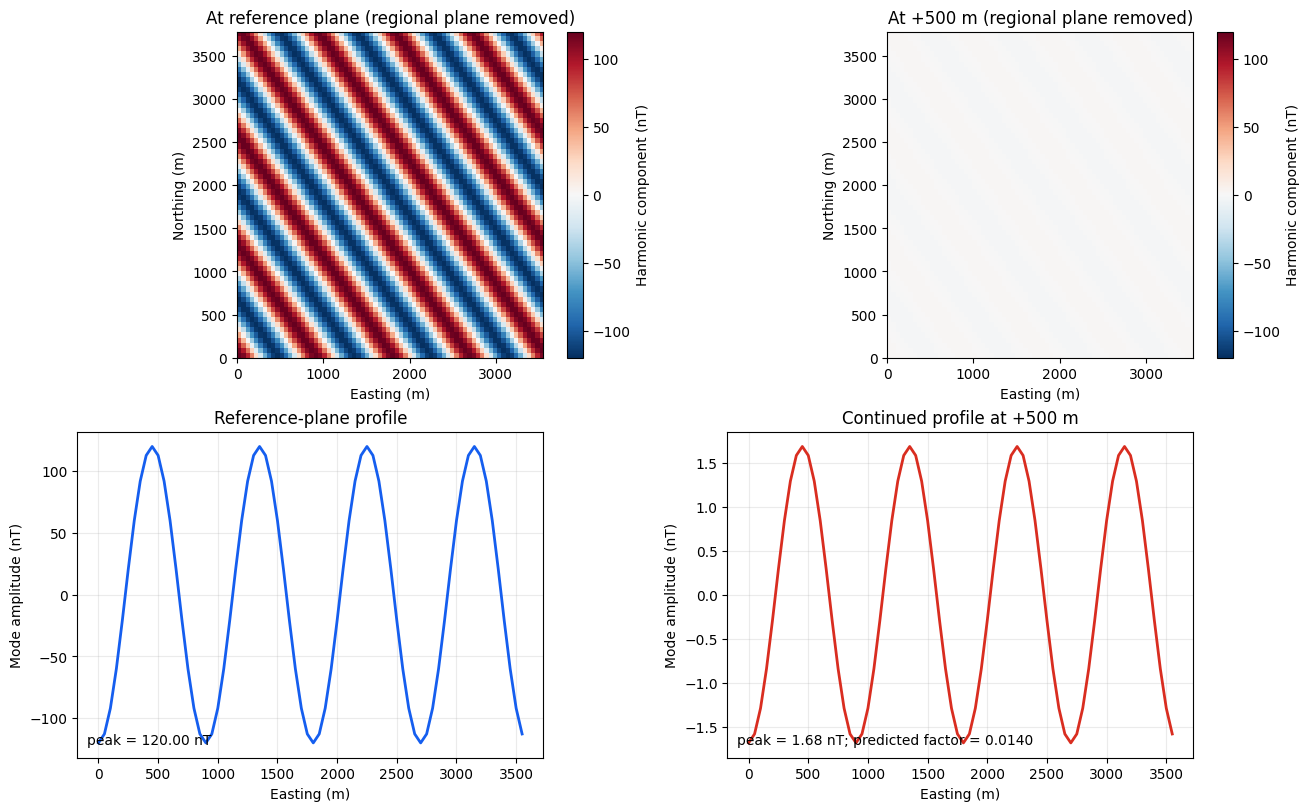

In [10]:
# This is a known-truth numerical control, not a measured Charleston grid.
import numpy as np
import matplotlib.pyplot as plt
from magnetic_continuation import upward_continue

ny, nx = 64, 72
dx, dy, height_m = 50.0, 60.0, 500.0
easting = np.arange(nx) * dx
northing = np.arange(ny) * dy
xx, yy = np.meshgrid(easting, northing, indexing="xy")
mode_x, mode_y, amplitude = 4, 3, 120.0
phase = 2 * np.pi * mode_x * xx / (nx * dx) + 2 * np.pi * mode_y * yy / (ny * dy)
regional = 50000.0 + 0.012 * xx - 0.018 * yy
observed = regional + amplitude * np.cos(phase)
continued_record = upward_continue(
    observed, spacing_easting_m=dx, spacing_northing_m=dy, height_m=height_m,
    support_mask=np.ones_like(observed, dtype=bool),
)
radial_k = np.hypot(2 * np.pi * mode_x / (nx * dx), 2 * np.pi * mode_y / (ny * dy))
attenuation = np.exp(-radial_k * height_m)
analytic = regional + amplitude * attenuation * np.cos(phase)
continued = np.asarray(continued_record["values"])
max_error = float(np.max(np.abs(continued - analytic)))
print(f"height={height_m:.0f} m; mode attenuation={attenuation:.6f}; max analytic error={max_error:.3e} nT")
print("FFT seam ratio:", continued_record["edge_periodicity_diagnostic"]["maximum_seam_jump_over_grid_std"])
assert max_error < 1e-8
assert np.max(np.abs(continued - regional)) < np.max(np.abs(observed - regional))

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
mode_observed = observed - regional
mode_continued = continued - regional
for ax, field, title in zip(axes[0], (mode_observed, mode_continued),
                            ("At reference plane (regional plane removed)", f"At +{height_m:.0f} m (regional plane removed)")):
    image = ax.imshow(field, origin="lower", extent=[easting[0], easting[-1], northing[0], northing[-1]],
                      cmap="RdBu_r", vmin=-amplitude, vmax=amplitude, aspect="equal")
    ax.set(title=title, xlabel="Easting (m)", ylabel="Northing (m)")
    fig.colorbar(image, ax=ax, label="Harmonic component (nT)")
axes[1, 0].plot(easting, mode_observed[ny // 2], color="#155eef", lw=2)
axes[1, 0].set(title="Reference-plane profile", xlabel="Easting (m)", ylabel="Mode amplitude (nT)")
axes[1, 0].text(.02, .04, f"peak = {np.max(np.abs(mode_observed[ny // 2])):.2f} nT",
                transform=axes[1, 0].transAxes, fontsize=10)
axes[1, 1].plot(easting, mode_continued[ny // 2], color="#d92d20", lw=2)
axes[1, 1].set(title=f"Continued profile at +{height_m:.0f} m", xlabel="Easting (m)", ylabel="Mode amplitude (nT)")
axes[1, 1].text(.02, .04, f"peak = {np.max(np.abs(mode_continued[ny // 2])):.2f} nT; predicted factor = {attenuation:.4f}",
                transform=axes[1, 1].transAxes, fontsize=10)
for ax in axes[1]: ax.grid(alpha=.25)
plt.show()

The discrete single mode loses the predicted factor \(e^{-kh}\), and the affine regional plane remains unchanged. This establishes implementation parity with the analytic Fourier operator for this periodic synthetic field. It does not validate the input grid, edge conditioning, survey corrections, provider processing, or geological interpretation. For a user grid, select a complete supported rectangular ROI, review the reported seam jump, and document any edge window applied before continuation.

In [11]:
# Missing cells must stop processing; silently filling them would invent field support.
from magnetic_continuation import ContinuationError
mask = np.ones((8, 8), dtype=bool)
mask[0, 0] = False
try:
    upward_continue(np.ones((8, 8)), spacing_easting_m=25, spacing_northing_m=25,
                    height_m=100, support_mask=mask)
except ContinuationError as error:
    print("expected refusal:", error)
else:
    raise AssertionError("unsupported cells were accepted")

expected refusal: upward continuation requires a complete true support mask


Expected result: `upward continuation requires a complete true support mask`.

### Run the M03 flight-line CSV processor

This section complements the geometry planner with the product’s actual M03 CSV workflow. The generated synthetic source file stays outside the repository under `CAOS_TEMP_ROOT`.


In [12]:
# Load the shared M03 pipeline and the scientific plotting tools.
import csv, hashlib, json, os, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / "data-pipeline"))
from magnetic_processing import read_csv, process
source_file = Path(os.environ["CAOS_TEMP_ROOT"]) / "m03-flightline-controlled.csv"
print("processor:", Path(sys.modules["magnetic_processing"].__file__).resolve().relative_to(root))
print("temporary CSV:", source_file.name)


processor: data-pipeline\magnetic_processing.py
temporary CSV: m03-flightline-controlled.csv


### Create a controlled survey

The field combines a regional gradient and two smooth anomalies. A fixed seed adds 0.25 nT Gaussian measurement noise. Eight parallel flight lines are 100 m apart; a tie line crosses them at x=525 m, between flight samples. One sensor-height sample is deliberately raised to 105 m. The tie observations receive +6 nT, which crossover QC should report without correcting. Coordinates use a declared local synthetic projected-metre frame.


In [13]:
# Generate a deterministic survey with one deliberate height anomaly and tie bias.
rng = np.random.default_rng(240518)
def field(x, y):
    return (50000.0 + .012*x - .018*y
        + 18*np.exp(-((x-690)**2/(2*190**2)+(y-335)**2/(2*170**2)))
        - 11*np.exp(-((x-300)**2/(2*135**2)+(y-610)**2/(2*110**2))))
rows = []
for i, y in enumerate(np.arange(0., 800., 100.)):
    line = f"F{i+1:02d}"
    for order, x in enumerate(np.arange(0., 1200.1, 100.)):
        height = 70 + 1.5*np.sin(order/3)
        if line == "F04" and order == 5: height = 105.0
        rows.append({"E_m":x,"N_m":y,"TMI_nT":field(x,y)+rng.normal(0,.25),"line":line,
                     "role":"flight","height_m":height,"order":order})
for order,y in enumerate(np.arange(0.,800.,100.)):
    x=525.
    rows.append({"E_m":x,"N_m":y,"TMI_nT":field(x,y)+6+rng.normal(0,.25),"line":"T01",
                 "role":"tie","height_m":72.,"order":order})
source_file.parent.mkdir(parents=True,exist_ok=True)
with source_file.open("w",newline="",encoding="utf-8") as stream:
    writer=csv.DictWriter(stream,fieldnames=list(rows[0])); writer.writeheader(); writer.writerows(rows)
print({"row_count":len(rows),"flight_lines":8,"tie_lines":1,"bytes":source_file.stat().st_size,
       "source_sha256":hashlib.sha256(source_file.read_bytes()).hexdigest()})


{'row_count': 112, 'flight_lines': 8, 'tie_lines': 1, 'bytes': 6742, 'source_sha256': 'b55120642f093b2d1c0463c15bb44c91aa48a6e746559d5568b158310076010c'}


### Run the shared product implementation

The CSV adapter hashes original bytes and accepts only the explicit seven-column map. The processor runs geometry and robust height QC, segment-interpolated line crossovers, a deterministic contiguous whole-line holdout, held-out prediction metrics, and a piecewise-linear Delaunay grid. Tie-line values are retained for QC but excluded from fitting. The 20% holdout and seed are fixed before results are inspected.


In [14]:
# Map each declared CSV column and execute the exact product processing functions.
field_map={"easting":"E_m","northing":"N_m","value":"TMI_nT","line_id":"line","line_role":"role","sensor_height_m":"height_m","sample_order":"order"}
source={"source_id":"synthetic:m03-flightline-controlled-v1","citation":"Notebook-authored analytic control; no external source",
 "rights_decision":"authored synthetic data","processing_state":"synthetic total-field values; deliberate +6 nT tie offset; no corrections",
 "value_unit":"nT","value_quantity":"synthetic total-field anomaly","sensor_height_reference":"above local synthetic ground"}
frame={"crs":"LOCAL:synthetic-projected-metres","coordinates_are_projected":True,"linear_unit":"m"}
settings={"grid_spacing_m":100.,"holdout_fraction":.20,"seed":"m03-bilingual-course-v1"}
request=read_csv(source_file,field_map=field_map,source_metadata=source,frame=frame,settings=settings)
result=process(request,source_hash_verified=True)
score=result["heldout_interpolation"]; qc=result["geometry_qc"]["crossover_interpolation_qc"]
height_flags=[(l["line_id"],l["sensor_height_m"]["qc_outlier_rows"]) for l in result["geometry_qc"]["lines"] if l["sensor_height_m"]["qc_outlier_rows"]]
print(json.dumps({"sha256":result["source"]["sha256"],"fit_lines":result["split"]["fit_line_ids"],
 "heldout_lines":result["split"]["holdout_line_ids"],"heldout_rows":score["heldout_row_count"],
 "supported_rows":score["supported_heldout_row_count"],"coverage":score["coverage_fraction"],
 "MAE_nT":score["mae"],"RMSE_nT":score["rmse"],"height_flags":height_flags,
 "crossover_count":qc["intersection_count"],"crossover_mean_signed_nT":qc["mean_signed_difference"],
 "grid_shape_yx":result["grid"]["shape_yx"],"supported_cells":int(np.asarray(result["grid"]["support_mask"]).sum()),
 "claims":result["claims"]},indent=2))
assert height_flags and qc["intersection_count"] > 0 and score["heldout_row_count"] > 0
assert result["claims"]["corrections_applied"] == [] and not result["claims"]["inverse_model"]


{
  "sha256": "b55120642f093b2d1c0463c15bb44c91aa48a6e746559d5568b158310076010c",
  "fit_lines": [
    "F01",
    "F02",
    "F03",
    "F04",
    "F05",
    "F08"
  ],
  "heldout_lines": [
    "F06",
    "F07"
  ],
  "heldout_rows": 26,
  "supported_rows": 26,
  "coverage": 1.0,
  "MAE_nT": 1.3886361098671982,
  "RMSE_nT": 1.9908756067541955,
  "height_flags": [
    [
      "F04",
      [
        5
      ]
    ]
  ],
  "crossover_count": 8,
  "crossover_mean_signed_nT": -5.9897483283457404,
  "grid_shape_yx": [
    8,
    13
  ],
  "supported_cells": 104,
  "claims": {
    "source_hash_recomputed_from_original_bytes": true,
    "corrections_applied": [],
    "provider_grid_comparison": false,
    "inverse_model": false,
    "scientific_release_accepted": false
  }
}


### Map the acquired rows and inspect crossover differences

The left view locates the exact input rows; flight and tie roles use different symbols. A ring marks the height-QC sample, while the measured magnetic value remains untouched. The right view plots segment-interpolated flight-minus-tie values. Their mean should be near the injected +6 nT, with deviation from noise and interpolation. This is a diagnostic, not a correction to apply automatically.


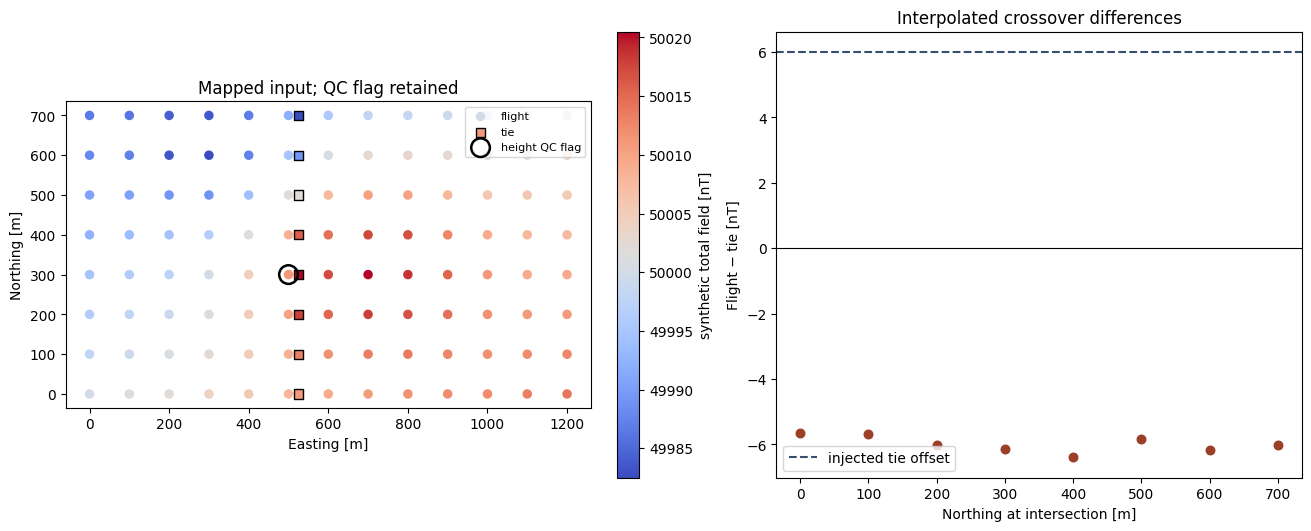

In [15]:
# Plot the input geometry and the processor-reported crossover diagnostics.
flight=[r for r in rows if r["role"]=="flight"]; tie=[r for r in rows if r["role"]=="tie"]
fig,ax=plt.subplots(1,2,figsize=(13,5.2),constrained_layout=True)
sc=ax[0].scatter([r["E_m"] for r in flight],[r["N_m"] for r in flight],c=[r["TMI_nT"] for r in flight],cmap="coolwarm",s=34,label="flight")
ax[0].scatter([r["E_m"] for r in tie],[r["N_m"] for r in tie],c=[r["TMI_nT"] for r in tie],cmap="coolwarm",marker="s",s=44,edgecolor="black",label="tie")
flag=next(r for r in rows if r["line"]=="F04" and r["order"]==5)
ax[0].scatter([flag["E_m"]],[flag["N_m"]],s=180,facecolors="none",edgecolors="black",linewidths=1.8,label="height QC flag")
ax[0].set(title="Mapped input; QC flag retained",xlabel="Easting [m]",ylabel="Northing [m]",aspect="equal"); ax[0].legend(fontsize=8); fig.colorbar(sc,ax=ax[0],label="synthetic total field [nT]")
crossings=qc["crossings"]
ax[1].scatter([c["northing_m"] for c in crossings],[c["difference_a_minus_b"] for c in crossings],color="#9b3f28",s=38)
ax[1].axhline(6,color="#344f70",linestyle="--",label="injected tie offset"); ax[1].axhline(0,color="black",lw=.8)
ax[1].set(title="Interpolated crossover differences",xlabel="Northing at intersection [m]",ylabel="Flight − tie [nT]"); ax[1].legend()
plt.show()


### Inspect the supported grid and held-out lines

The grid fits flight observations only. Gray cells have a false support mask; the stored zero there is an encoding, not a physical measurement. Orange crosses show the entire held-out flight lines. Read coverage beside MAE/RMSE: low error over a small supported fraction would not mean broad survey coverage.


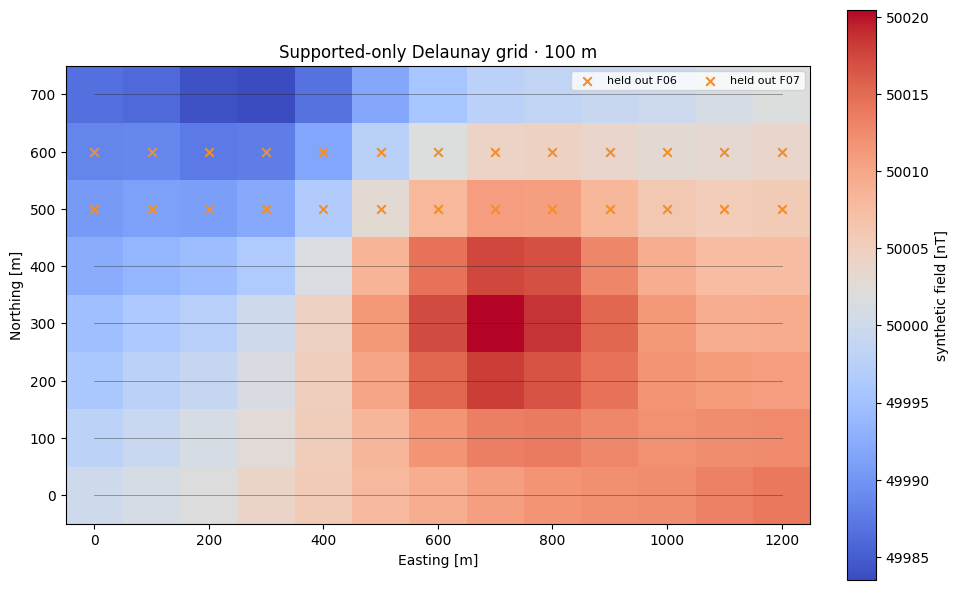

Held-out interpolation: 26/26 supported; coverage=100.0%; MAE=1.389 nT; RMSE=1.991 nT


In [16]:
# Render the returned values only where the product support mask is true.
g=result["grid"]; x=np.asarray(g["x_easting_m"]); y=np.asarray(g["y_northing_m"])
values=np.asarray(g["values"],float); mask=np.asarray(g["support_mask"],bool)
fig,ax=plt.subplots(figsize=(9.5,5.8),constrained_layout=True)
mesh=ax.pcolormesh(x,y,np.ma.masked_where(~mask,values),shading="nearest",cmap="coolwarm")
for line_id in result["split"]["fit_line_ids"]:
    line=[r for r in flight if r["line"]==line_id]; ax.plot([r["E_m"] for r in line],[r["N_m"] for r in line],color="#222",lw=.6,alpha=.45)
for line_id in result["split"]["holdout_line_ids"]:
    line=[r for r in flight if r["line"]==line_id]; ax.scatter([r["E_m"] for r in line],[r["N_m"] for r in line],marker="x",color="#f28e2b",s=38,label=f"held out {line_id}")
ax.set(title="Supported-only Delaunay grid · 100 m",xlabel="Easting [m]",ylabel="Northing [m]",aspect="equal"); ax.legend(ncol=2,fontsize=8); fig.colorbar(mesh,ax=ax,label="synthetic field [nT]")
plt.show()
print(f"Held-out interpolation: {score['supported_heldout_row_count']}/{score['heldout_row_count']} supported; coverage={score['coverage_fraction']:.1%}; MAE={score['mae']:.3f} nT; RMSE={score['rmse']:.3f} nT")


### Change grid spacing: sampling is not resolution

The 200 m run uses the same CSV bytes, map, seed, holdout and interpolator. Only the output grid sampling changes. Its held-out score should be identical because scoring evaluates the same continuous piecewise-linear interpolator at held-out coordinates. A denser raster is not added geological information.


In [17]:
# Change grid spacing while holding data, split, and interpolation fixed.
coarse_settings={**settings,"grid_spacing_m":200.}
coarse_request=read_csv(source_file,field_map=field_map,source_metadata=source,frame=frame,settings=coarse_settings)
coarse=process(coarse_request,source_hash_verified=True); coarse_score=coarse["heldout_interpolation"]
print({"grid_100m":result["grid"]["shape_yx"],"grid_200m":coarse["grid"]["shape_yx"],
 "same_holdout":result["split"]["holdout_line_ids"]==coarse["split"]["holdout_line_ids"],
 "same_RMSE":score["rmse"]==coarse_score["rmse"],"RMSE_100m_nT":score["rmse"],"RMSE_200m_nT":coarse_score["rmse"]})
assert result["split"]["holdout_line_ids"]==coarse["split"]["holdout_line_ids"]
assert score["rmse"]==coarse_score["rmse"] and result["grid"]["shape_yx"]!=coarse["grid"]["shape_yx"]


{'grid_100m': [8, 13], 'grid_200m': [4, 7], 'same_holdout': True, 'same_RMSE': True, 'RMSE_100m_nT': 1.9908756067541955, 'RMSE_200m_nT': 1.9908756067541955}


### Interpretation and limits

The shared implementation parsed the mapped CSV, reported the injected height and crossover conditions, held out complete flight lines, calculated a support-masked interpolation grid and scored held-out rows. It applied no tie-line levelling or other correction. Coarser grid spacing changed array sampling but left validation metrics unchanged.

This experiment does **not** establish field accuracy, provider-grid equivalence, geological truth, diurnal/IGRF/lag/terrain corrections, a magnetic inverse model, or safe browser execution. The analytic truth is known only because the notebook authored the generator. Real data require documented rights, CRS/datum, units, acquisition order and processing history, with independent source-specific validation.

### References

- Li (2006), *Understanding 3D analytic signal amplitude*, Geophysics 71(2), L13–L16. [doi:10.1190/1.2184367](https://doi.org/10.1190/1.2184367). Context only; no inverse is performed here.
- SciPy [`LinearNDInterpolator`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.LinearNDInterpolator.html): piecewise-linear interpolation on a Qhull Delaunay triangulation.
- Product source: `data-pipeline/magnetic_processing.py`; requirements: `docs/design/features/m03-flightline-processing/requirements.md`.


## Results

The geometry planner verifies schema and spatial partition construction, not a measured prediction. The continuation experiment executes the product Fourier operator against closed-form synthetic truth. The flight-line control executes the exact production CSV adapter and processor: it reports the injected height flag and tie discrepancy, computes a deterministic whole-line holdout, evaluates interpolation coverage/error, and returns a support-masked grid. Coarsening the grid leaves holdout metrics unchanged. On failure, retain the refusal; do not shrink buffers or synthesize field measurements.

The planner creates indivisible units by joining shared flight groups and spatial blocks, then seals an outer holdout and buffered folds. Since it plans from metadata, its deterministic output is not a prediction score. The continuation calculation uses an exactly periodic field and affine regional plane. The line-processing control is a separate authored analytic survey; none of these outputs provide provider-specific field accuracy.


## Summary

The 72-row outer holdout and buffered-fold plan are computed for an authored geometry fixture. A known-truth Fourier control verifies upward continuation of one harmonic mode while preserving an affine plane. The shared M03 line processor also passes a synthetic CSV through source hashing, height and crossover QC, blocked-line holdout and support-masked gridding; a grid-spacing change alters array sampling but not the held-out score. No measured provider survey is included, and corrections, leveling, provider-grid comparison, field validity and subsurface inversion remain outside this evidence.


## References

- Blakely, R. J. (1995), *Potential Theory in Gravity and Magnetic Applications*, Cambridge University Press, Chapter 12. [Book reference](https://www.cambridge.org/core/books/potential-theory-in-gravity-and-magnetic-applications/).
- [Verde spatial train/test split](https://www.fatiando.org/verde/latest/api/generated/verde.train_test_split.html).
